In [1]:
# Setup: move to repo root, import the raster module, list the NWB recordings
# (batch export from a shell: python -m src.visualization.rasters data/raw/*.nwb)
import os, sys
from pathlib import Path
# Move to repo root so `src` is importable and data paths resolve
root = Path.cwd()
while not (root / "src").is_dir():
    root = root.parent
os.chdir(root); sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
from src.visualization import rasters

SESSIONS = sorted(Path("data/raw").glob("*.nwb"))
SESSIONS

[WindowsPath('data/raw/688277-20230921-v001.nwb'),
 WindowsPath('data/raw/692644-20230907-v001.nwb')]

In [2]:
# Show which conditions each recording contains and their time windows
for path in SESSIONS:
    with rasters.open_session(path) as nwb:
        print(path.name, '|', nwb.pharmacology)
        display(rasters.condition_windows(nwb))

688277-20230921-v001.nwb | isoflurane (inhalation): induction at 5%, maintenance at 1.5%


,condition,label,start,stop,n_trials
0,awake,awake,319.39348,1990.20594,240
1,isoflurane,isoflurane,2780.52522,4451.33563,240


692644-20230907-v001.nwb | 1st injection: saline (0.01 mL/g, i.p.); 2nd injection: psilocybin (1 mg/kg, i.p.)


,condition,label,start,stop,n_trials
0,awake,awake,789.75000,2460.56249,240
1,psilocybin,psilocybin,4043.36793,5714.17847,240


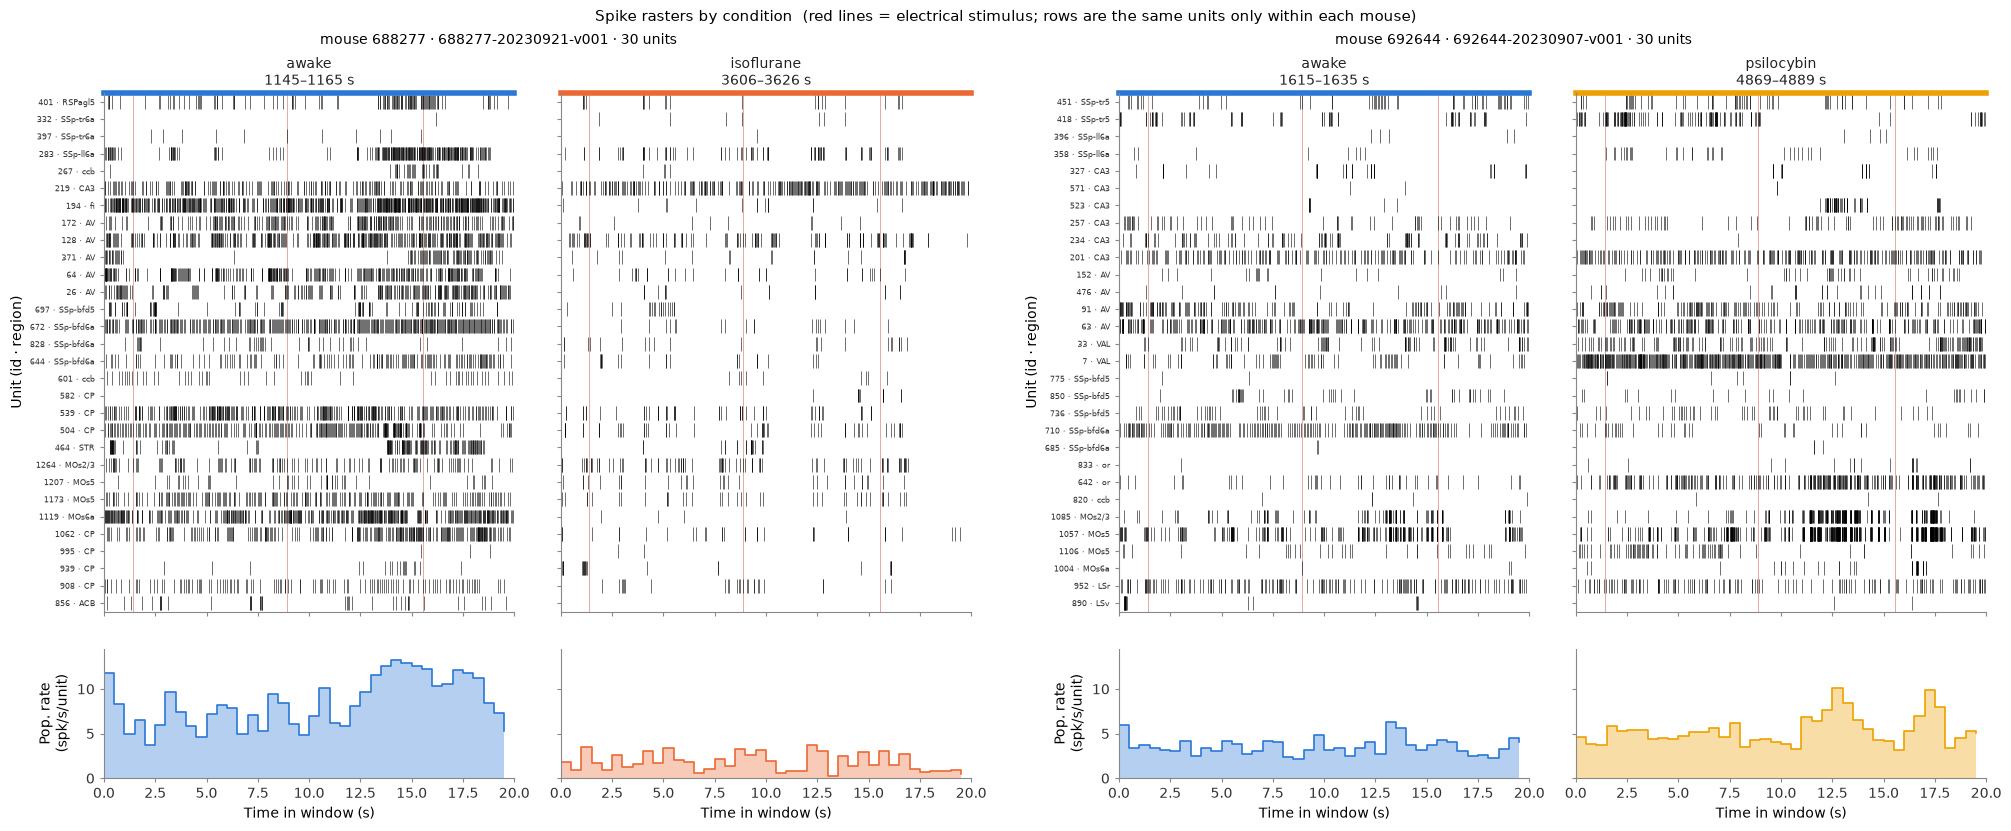

In [3]:
# Main figure: all conditions side by side (same units within each mouse; red lines = stimulus)
fig = rasters.plot_session_rasters(SESSIONS, n_units=30, window=20)
plt.show()

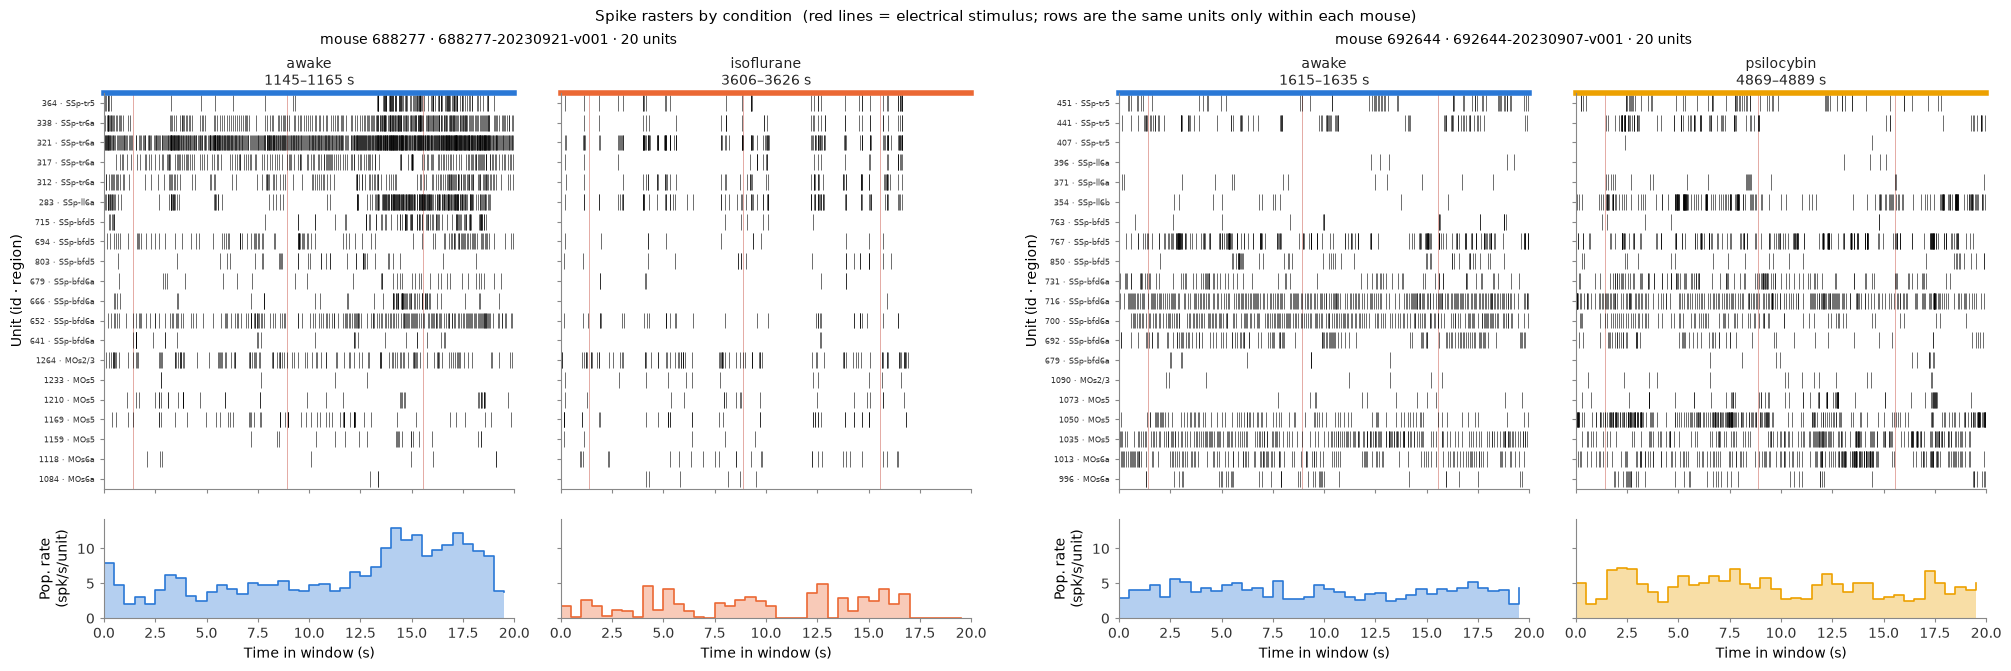

In [4]:
# Same figure restricted to cortex units (somatosensory + motor)
fig = rasters.plot_session_rasters(SESSIONS, n_units=20, regions=["SSp", "MOs"])
plt.show()

In [5]:
# Look up unit ids/regions to pick specific units per recording
with rasters.open_session(SESSIONS[0]) as nwb:
    display(rasters.select_units(nwb, n=None)[["location", "probe", "n_spikes"]].head(10))

# fig = rasters.plot_session_rasters(SESSIONS, unit_ids={SESSIONS[0]: [643, 490, 103],
#                                                        SESSIONS[1]: [203, 146, 7]})

,location,probe,n_spikes
unit_id,,,
401,RSPagl5,probeB,17896
364,SSp-tr5,probeB,22879
355,SSp-tr5,probeB,22774
353,SSp-tr5,probeB,3914
347,SSp-tr5,probeB,33746
348,SSp-tr5,probeB,8832
349,SSp-tr5,probeB,19684
337,SSp-tr6a,probeB,50772
338,SSp-tr6a,probeB,34901
